In [53]:
#1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
file_path = r"D:\ESE5023\earthquakes-2026-10-14_20-30-33_+0800.tsv"
Sig_Eqs = pd.read_csv(file_path, sep="\t")
Sig_Eqs.columns

Index(['Search Parameters', 'Id', 'Year', 'Mo', 'Dy', 'Hr', 'Mn', 'Sec', 'Tsu',
       'Vol', 'Country', 'Area', 'Region', 'Location Name', 'Latitude',
       'Longitude', 'Focal Depth (km)', 'Mag', 'Mw', 'Ms', 'Mb', 'Ml', 'Mfa',
       'Unk', 'MMI Int', 'Deaths', 'Death Description', 'Missing',
       'Missing Description', 'Injuries', 'Injuries Description',
       'Damage ($Mil)', 'Damage Description', 'Houses Destroyed',
       'Houses Destroyed Description', 'Houses Damaged',
       'Houses Damaged Description', 'Total Deaths', 'Total Death Description',
       'Total Missing', 'Total Missing Description', 'Total Injuries',
       'Total Injuries Description', 'Total Damage ($Mil)',
       'Total Damage Description', 'Total Houses Destroyed',
       'Total Houses Destroyed Description', 'Total Houses Damaged',
       'Total Houses Damaged Description'],
      dtype='str')

In [54]:
#1.1
deaths = Sig_Eqs.groupby("Country")["Total Deaths"].sum(min_count=1)
deaths = deaths.sort_values(ascending=False)
deaths.head(20)

Country
CHINA           2106526.0
TURKEY          1008867.0
IRAN             761656.0
SYRIA            488326.0
ITALY            417297.0
HAITI            323782.0
JAPAN            319510.0
AZERBAIJAN       319251.0
INDONESIA        283485.0
ARMENIA          175000.0
PAKISTAN         143714.0
ECUADOR          134445.0
TURKMENISTAN     110412.0
PERU              97009.0
GREECE            83658.0
PORTUGAL          82572.0
IRAQ              70200.0
CHILE             70175.0
INDIA             63413.0
ISRAEL            58368.0
Name: Total Deaths, dtype: float64

Year
-2000.0    1
-479.0     1
-426.0     1
-400.0     1
-373.0     1
          ..
 2015.0    1
 2017.0    1
 2019.0    1
 2024.0    1
 2025.0    3
Length: 511, dtype: int64


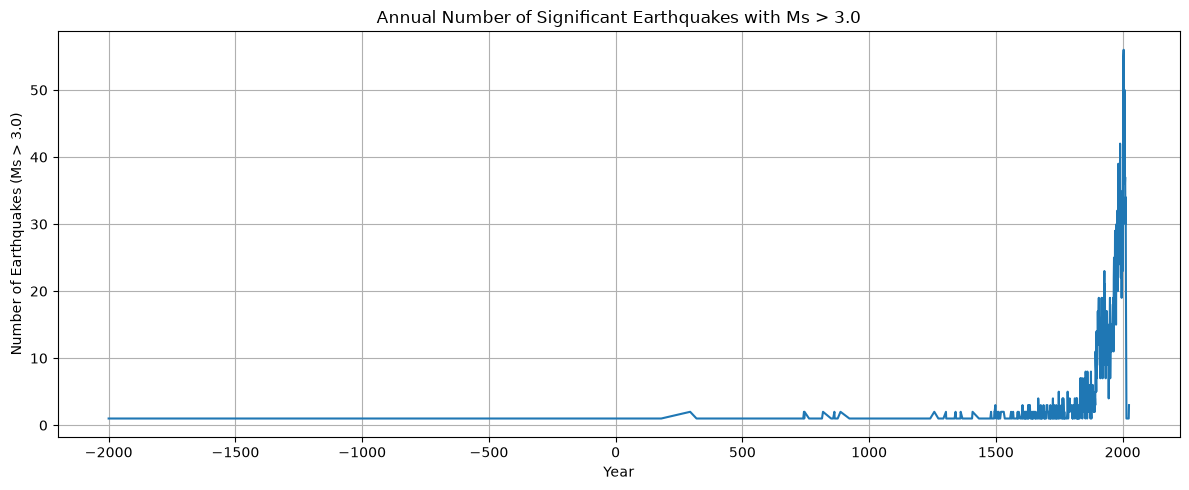

In [55]:
#1.2
Sig_Eqs["Ms"] = pd.to_numeric(Sig_Eqs["Ms"], errors="coerce")
Sig_Eqs["Year"] = pd.to_numeric(Sig_Eqs["Year"], errors="coerce")
valid_eq = Sig_Eqs.dropna(subset=["Ms", "Year"])
valid_eq = valid_eq[valid_eq["Ms"] > 3.0]
earthquakes_per_year = valid_eq.groupby("Year").size()
earthquakes_per_year = earthquakes_per_year.sort_index()
print(earthquakes_per_year)

plt.figure(figsize=(12, 5))
plt.plot(earthquakes_per_year.index,earthquakes_per_year.values)
plt.xlabel("Year")
plt.ylabel("Number of Earthquakes (Ms > 3.0)")
plt.title("Annual Number of Significant Earthquakes with Ms > 3.0")
plt.grid(True)
plt.tight_layout()
plt.show()

In [56]:
#1.3
def CountEq_LargestEq(country):
    country_data = Sig_Eqs[Sig_Eqs["Country"] == country]
    total_earthquakes = len(country_data)
    valid_data = country_data.dropna(subset=["Ms"])
    if valid_data.empty:
        return total_earthquakes, None, None
    largest_eq = valid_data.loc[valid_data["Ms"].idxmax()]
    year = largest_eq["Year"]
    month = largest_eq["Mo"]
    day = largest_eq["Dy"]
    date = f"{year}-{month}-{day}"
    location = largest_eq["Location Name"]
    return total_earthquakes, date, location

In [57]:
#1.3
countries = Sig_Eqs["Country"].dropna().unique()
results = []

for country in countries:
    count, date, location = CountEq_LargestEq(country)
    results.append({
        "Country": country,
        "Total_Earthquakes": count,
        "Largest_Earthquake_Date": date,
        "Largest_Earthquake_Location": location
    })

Results_df = pd.DataFrame(results)
Results_df = Results_df.sort_values(
    by="Total_Earthquakes",
    ascending=False
)

print(Results_df.to_string(index=False))

                                     Country  Total_Earthquakes Largest_Earthquake_Date                          Largest_Earthquake_Location
                                       CHINA                626        1920.0-12.0-16.0              CHINA:  GANSU PROVINCE, SHANXI PROVINCE
                                       JAPAN                429          869.0-7.0-13.0                                      JAPAN:  SANRIKU
                                   INDONESIA                427        2004.0-12.0-26.0          INDONESIA:  SUMATRA:  ACEH:  OFF WEST COAST
                                        IRAN                385         856.0-12.0-22.0                                IRAN:  DAMGHAN, QUMIS
                                      TURKEY                359        1939.0-12.0-26.0                                    TURKEY:  ERZINCAN
                                       ITALY                338         1915.0-1.0-13.0                   ITALY:  MARSICA, AVEZZANO, ABRUZZI
             

Valid records: 234864


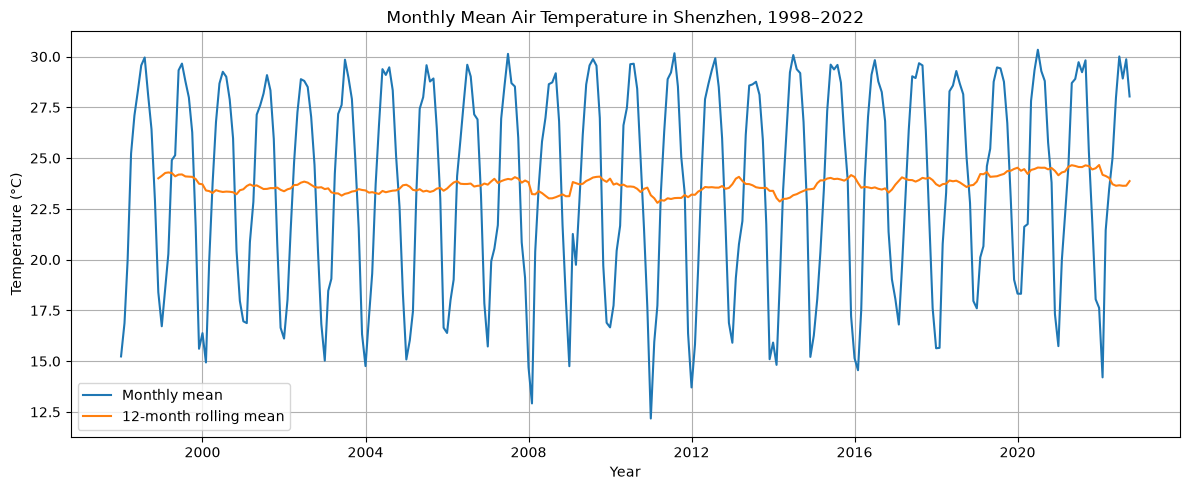

Trend: 0.0388 °C/year
P-value: 0.3381
The linear trend is not statistically significant.


In [58]:
#2
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

file_path = r"D:\ESE5023\Baoan_Weather_1998_2022.csv"
df = pd.read_csv(file_path, usecols=["DATE", "TMP"])

df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce")
tmp = df["TMP"].astype("string").str.split(",", expand=True)
temp = pd.to_numeric(tmp[0], errors="coerce")
df["TMP_QC"] = tmp[1].str.strip()

# +9999表示缺失值，气温除以10转换为摄氏度
df["Temperature"] = temp.mask(temp == 9999) / 10

# 筛选有效数据
clean = df[
    df["DATE"].notna()
    & df["Temperature"].notna()
    & df["TMP_QC"].isin(["1", "5"])
    & (df["DATE"] >= "1998-01-01")
    & (df["DATE"] < "2023-01-01")
].copy()
print("Valid records:", len(clean))

# 计算月平均气温
clean = clean.set_index("DATE").sort_index()
monthly_temp = clean["Temperature"].resample("MS").mean()
months = pd.date_range("1998-01-01", "2022-12-01", freq="MS")
monthly_temp = monthly_temp.reindex(months)
#绘图 线性分析
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_temp.index,
    monthly_temp.values,
    label="Monthly mean"
)

plt.plot(
    monthly_temp.index,
    monthly_temp.rolling(12, min_periods=12).mean(),
    label="12-month rolling mean"
)

plt.xlabel("Year")
plt.ylabel("Temperature (°C)")
plt.title("Monthly Mean Air Temperature in Shenzhen, 1998–2022")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

valid = monthly_temp.dropna()
years = valid.index.year + (valid.index.month - 1) / 12
slope, intercept, r, p, se = linregress(years, valid.values)
print("Trend:", round(slope, 4), "°C/year")
print("P-value:", round(p, 4))

if p < 0.05:
    print("The linear trend is statistically significant.")
else:
    print("The linear trend is not statistically significant.")


In [59]:
import pandas as pd
import matplotlib.pyplot as plt
#3 读取信息
file_path = r"D:\ESE5023\ibtracs.ALL.list.v04r00.csv"
df = pd.read_csv(
    file_path,
    usecols=range(17),
    skiprows=[1, 2],
    parse_dates=["ISO_TIME"],
    na_values=["NOT_NAMED", "NAME"],
    low_memory=False
)

df.head()

,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG
0,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 06:00:00,NR,10.8709,79.8265,,,,main,0,0,__________P___
1,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 09:00:00,NR,10.8431,79.3524,,,,main,0,0,__________P___
2,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 12:00:00,NR,10.8188,78.8772,,,,main,0,0,__________P___
3,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 15:00:00,NR,10.8000,78.4000,,,,main,0,0,__________O___
4,1842298N11080,1842,1,NI,AS,NaN,1842-10-25 18:00:00,NR,10.7884,77.9194,,,,main,0,0,__________P___


In [60]:
#3.1
df["WMO_WIND"] = pd.to_numeric(df["WMO_WIND"], errors="coerce")
df["LAT"] = pd.to_numeric(df["LAT"], errors="coerce")
df["LON"] = pd.to_numeric(df["LON"], errors="coerce")
storm_wind = df.groupby("SID").agg(
    NAME=("NAME", "first"),
    WMO_WIND=("WMO_WIND", "max")
)

top10 = storm_wind.dropna(subset=["WMO_WIND"]).sort_values(
    "WMO_WIND", ascending=False
).head(10)

print(top10)

                   NAME  WMO_WIND
SID                              
2015293N13266  PATRICIA     185.0
1980214N11330     ALLEN     165.0
2005289N18282     WILMA     160.0
1997253N12255     LINDA     160.0
1988253N12306   GILBERT     160.0
1935241N23291       NaN     160.0
2019236N10314    DORIAN     160.0
2009288N07267      RICK     155.0
1998295N12284     MITCH     155.0
2017242N16333      IRMA     155.0


In [61]:
#3.2
top20 = storm_wind.dropna(subset=["WMO_WIND"]).sort_values(
    "WMO_WIND", ascending=False
).head(20)

print(top20[["NAME", "WMO_WIND"]])

                   NAME  WMO_WIND
SID                              
2015293N13266  PATRICIA     185.0
1980214N11330     ALLEN     165.0
2005289N18282     WILMA     160.0
1997253N12255     LINDA     160.0
1988253N12306   GILBERT     160.0
1935241N23291       NaN     160.0
2019236N10314    DORIAN     160.0
2009288N07267      RICK     155.0
1998295N12284     MITCH     155.0
2017242N16333      IRMA     155.0
2005261N21290      RITA     155.0
2017260N12310     MARIA     150.0
1955265N13307     JANET     150.0
1979238N12324     DAVID     150.0
1977242N27272     ANITA     150.0
2007244N12303     FELIX     150.0
2007225N12331      DEAN     150.0
2005236N23285   KATRINA     150.0
1994222N11267      JOHN     150.0
1992230N11325    ANDREW     150.0


In [62]:
#3.3
basin_counts = df["BASIN"].value_counts()
print(basin_counts)

BASIN
WP    236576
SI    160668
SP     67119
EP     62412
NI     55401
SA       119
Name: count, dtype: int64


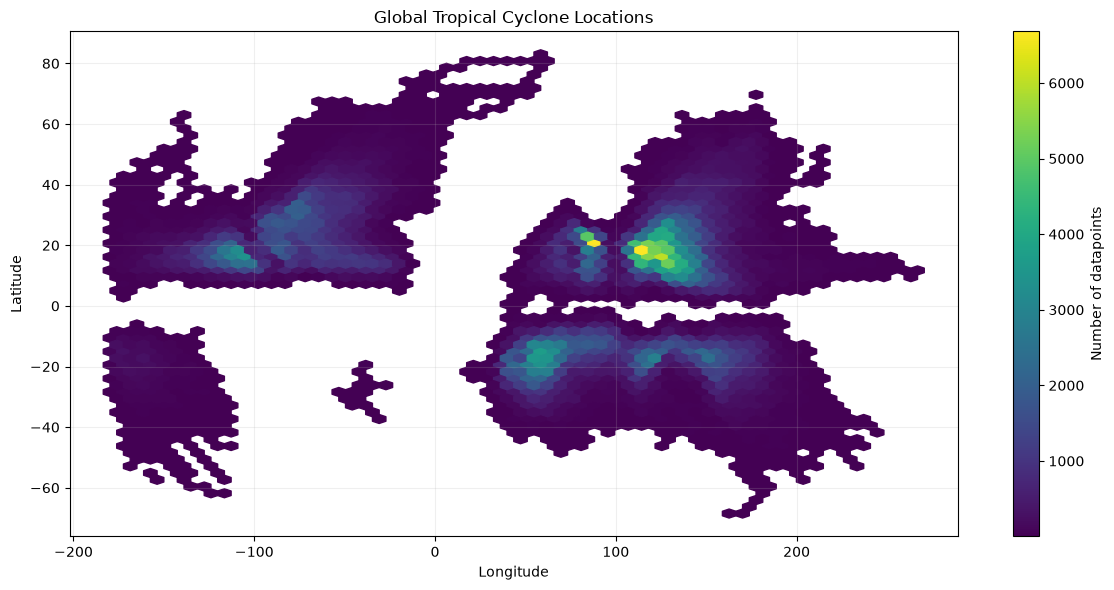

In [63]:
#3.4
locations = df.dropna(subset=["LAT", "LON"])

plt.figure(figsize=(12, 6))

plt.hexbin(
    locations["LON"],
    locations["LAT"],
    gridsize=60,
    mincnt=1,
    cmap="viridis"
)

plt.colorbar(label="Number of datapoints")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Global Tropical Cyclone Locations")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

            NAME            ISO_TIME      LAT      LON  WMO_WIND
683018  MANGKHUT 2018-09-06 12:00:00  11.8000  170.200       NaN
683019  MANGKHUT 2018-09-06 15:00:00  11.9275  169.745       NaN
683020  MANGKHUT 2018-09-06 18:00:00  12.0000  169.225       NaN
683021  MANGKHUT 2018-09-06 21:00:00  12.0302  168.564       NaN
683022  MANGKHUT 2018-09-07 00:00:00  12.0875  167.875       NaN


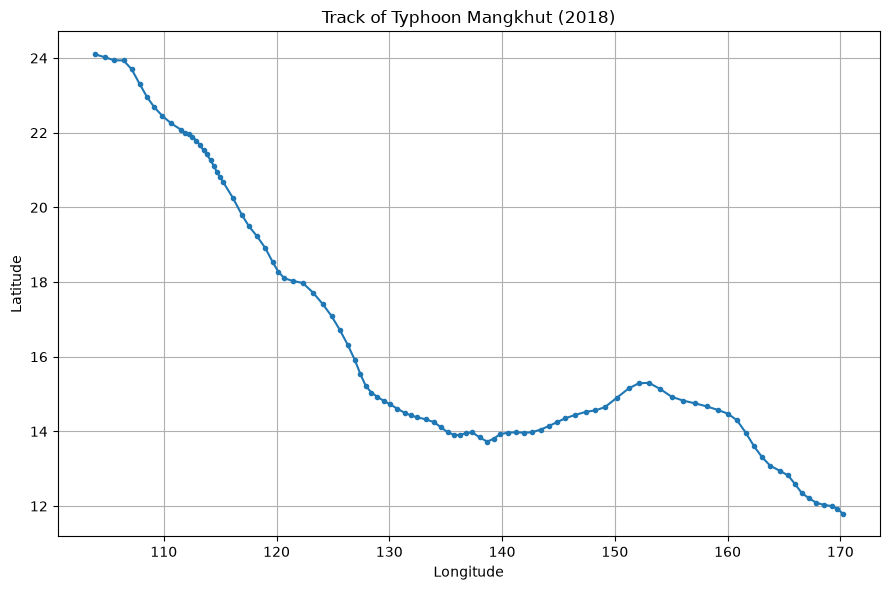

In [64]:
#3.5
mangkhut = df[
    (df["NAME"].astype("string").str.strip().str.upper() == "MANGKHUT")
    & (df["ISO_TIME"].dt.year == 2018)
].dropna(subset=["LAT", "LON"]).sort_values("ISO_TIME")

print(mangkhut[["NAME", "ISO_TIME", "LAT", "LON", "WMO_WIND"]].head())

plt.figure(figsize=(9, 6))

plt.plot(
    mangkhut["LON"],
    mangkhut["LAT"],
    marker="o",
    markersize=3
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Track of Typhoon Mangkhut (2018)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [65]:
#3.6
filtered = df[
    (df["ISO_TIME"] >= "1970-01-01")
    & (df["BASIN"].isin(["WP", "EP"]))
].copy()

print(filtered.head())
print("Number of datapoints:", len(filtered))
print("Basins:", filtered["BASIN"].unique())

                  SID  SEASON  NUMBER BASIN SUBBASIN   NAME  \
350393  1970050N07151    1970      22    WP       MM  NANCY   
350394  1970050N07151    1970      22    WP       MM  NANCY   
350395  1970050N07151    1970      22    WP       MM  NANCY   
350396  1970050N07151    1970      22    WP       MM  NANCY   
350397  1970050N07151    1970      22    WP       MM  NANCY   

                  ISO_TIME NATURE      LAT      LON  WMO_WIND WMO_PRES  \
350393 1970-02-19 00:00:00     TS  7.00000  151.400       NaN     1006   
350394 1970-02-19 03:00:00     TS  7.24752  151.205       NaN            
350395 1970-02-19 06:00:00     TS  7.50000  151.000       NaN     1002   
350396 1970-02-19 09:00:00     TS  7.75747  150.772       NaN            
350397 1970-02-19 12:00:00     TS  8.00000  150.500       NaN      998   

       WMO_AGENCY TRACK_TYPE  DIST2LAND LANDFALL           IFLAG  
350393      tokyo       main       1088     1088  _OO___________  
350394                  main       1109   

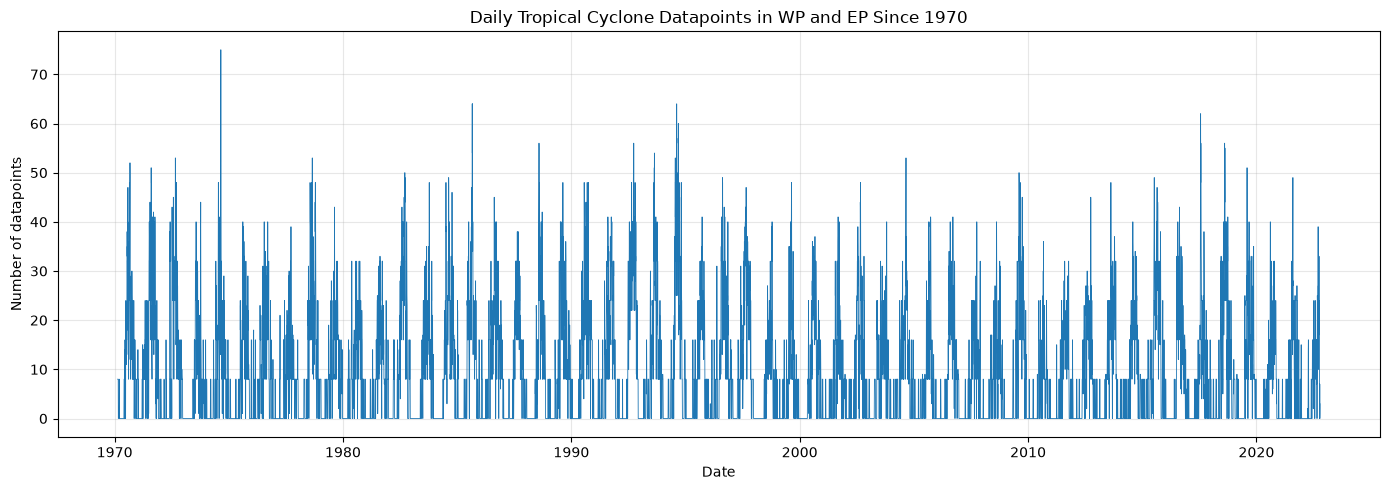

In [66]:
#3.7
daily_counts = (
    filtered.set_index("ISO_TIME")
    .sort_index()
    .resample("D")
    .size()
)

all_days = pd.date_range(
    daily_counts.index.min().normalize(),
    daily_counts.index.max().normalize(),
    freq="D"
)

daily_counts = daily_counts.reindex(all_days, fill_value=0)
daily_counts.index.name = "Date"

plt.figure(figsize=(14, 5))

plt.plot(daily_counts.index, daily_counts.values, linewidth=0.6)

plt.xlabel("Date")
plt.ylabel("Number of datapoints")
plt.title("Daily Tropical Cyclone Datapoints in WP and EP Since 1970")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [67]:
#3.8
# 提取一年中的日期序号（1—366）
day_of_year = daily_counts.index.dayofyear

# 计算每个 day of year 的多年平均数据点数量
climatology = daily_counts.groupby(day_of_year).mean()

print(climatology.head())

Date
1    1.596154
2    1.384615
3    1.423077
4    1.788462
5    2.019231
dtype: float64


In [68]:
#3.9
daily_climatology = daily_counts.index.dayofyear.map(climatology)

# 实际数量减去气候态
anomaly = daily_counts - daily_climatology

print(anomaly.head())

Date
1970-02-19    7.018868
1970-02-20    7.094340
1970-02-21    7.188679
1970-02-22    7.377358
1970-02-23    7.490566
Freq: D, dtype: float64


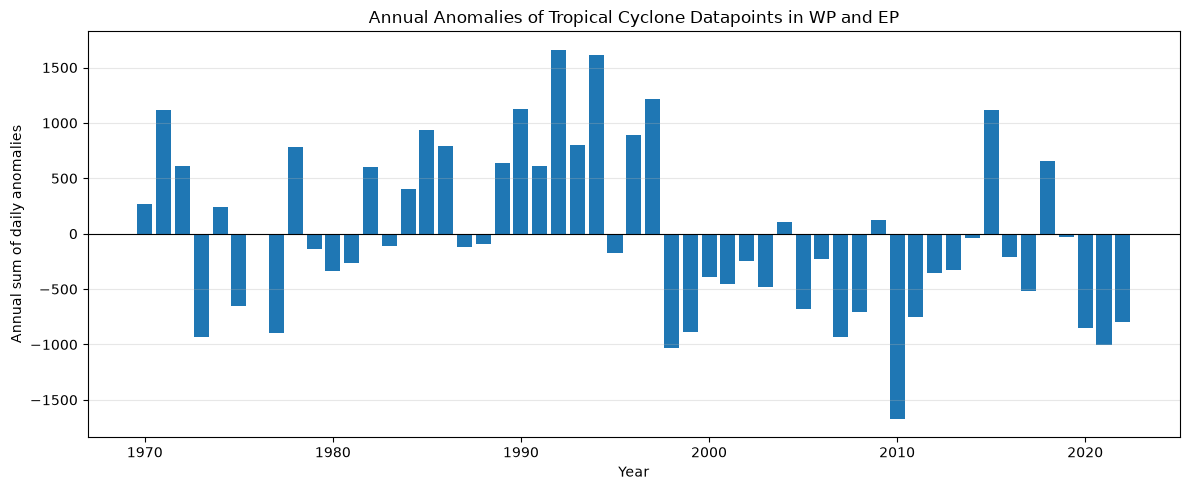

Years with the highest annual anomalies:
Date
1992-12-31    1660.725327
1994-12-31    1611.725327
1997-12-31    1215.725327
1990-12-31    1121.725327
2015-12-31    1119.725327
dtype: float64

Years with the lowest annual anomalies:
Date
2010-12-31   -1668.274673
1998-12-31   -1033.274673
2021-12-31   -1004.274673
2007-12-31    -935.274673
1973-12-31    -933.274673
dtype: float64


In [69]:

annual_anomaly = anomaly.resample("YE").sum()

plt.figure(figsize=(12, 5))

plt.bar(
    annual_anomaly.index.year,
    annual_anomaly.values
)

plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Year")
plt.ylabel("Annual sum of daily anomalies")
plt.title("Annual Anomalies of Tropical Cyclone Datapoints in WP and EP")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 找出异常值总和最高和最低的年份
print("Years with the highest annual anomalies:")
print(annual_anomaly.sort_values(ascending=False).head(5))

print("\nYears with the lowest annual anomalies:")
print(annual_anomaly.sort_values().head(5))

Dataset Information
Records: 245
Variables: 27
Data Quality Check
Surface samples: 163
Missing temperatures: 8
Missing dates: 0
Missing temperature percentage: 4.91%
Valid observations: 155
Date range: 2025-04-28 to 2025-10-20
Descriptive Statistics
count    155.00
mean      21.65
std        3.88
min       11.43
25%       18.66
50%       21.85
75%       25.15
max       28.20
Name: Temp_C, dtype: float64
Range: 16.76 °C
Monthly Temperature Results
            Mean_Temp_C  Sample_Count  Monthly_Change_C
Date                                                   
2025-04-01        13.66             8               NaN
2025-05-01        16.61             8              2.95
2025-06-01        21.18            32              4.57
2025-07-01        26.10            32              4.92
2025-08-01        23.93            18             -2.17
2025-09-01        21.33            39             -2.59
2025-10-01        18.76            18             -2.57
Monthly Temperature Changes
2025-04 to 2025-0

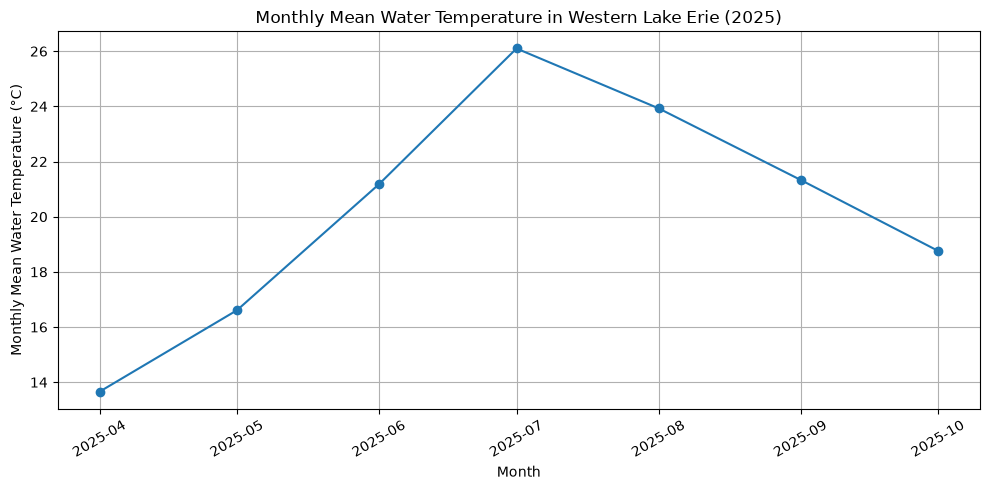

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 数据读取
file_path = r"D:\ESE5023\2025_WLE_Weekly_Datashare_CSV.csv"
df = pd.read_csv(file_path)

print("Dataset Information")
print("Records:", len(df))
print("Variables:", len(df.columns))

#数据清洗
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Temp_C"] = pd.to_numeric(df["Temp_C"], errors="coerce")

surface = df[
    df["Sample_Depth_category"].astype(str).str.strip() == "S"
].copy()

print("Data Quality Check")
print("Surface samples:", len(surface))
print("Missing temperatures:", surface["Temp_C"].isna().sum())
print("Missing dates:", surface["Date"].isna().sum())

missing_pct = surface["Temp_C"].isna().mean() * 100
print(f"Missing temperature percentage: {missing_pct:.2f}%")

valid = surface.dropna(subset=["Date", "Temp_C"]).copy()

print("Valid observations:", len(valid))
print("Date range:", valid["Date"].min().date(),
      "to", valid["Date"].max().date())

#统计检查
temperature = valid["Temp_C"]

print("Descriptive Statistics")
print(temperature.describe().round(2))
print(f"Range: {temperature.max() - temperature.min():.2f} °C")

#计算月平均水温和每月样本数量
monthly = (
    valid.set_index("Date")["Temp_C"]
    .resample("MS")
    .agg(["mean", "count"])
)

monthly.columns = ["Mean_Temp_C", "Sample_Count"]
monthly["Monthly_Change_C"] = monthly["Mean_Temp_C"].diff()

print("Monthly Temperature Results")
print(monthly.round(2).to_string())

#水温变化
print("Monthly Temperature Changes")

for start, end in [
    ("2025-04-01", "2025-07-01"),
    ("2025-07-01", "2025-10-01")
]:
    if start in monthly.index.strftime("%Y-%m-%d").tolist() and \
       end in monthly.index.strftime("%Y-%m-%d").tolist():
        change = monthly.loc[end, "Mean_Temp_C"] - monthly.loc[start, "Mean_Temp_C"]
        print(f"{start[:7]} to {end[:7]}: {change:.2f} °C")
    else:
        print(f"Missing monthly data: {start[:7]} or {end[:7]}")

#线性分析
monthly_valid = monthly["Mean_Temp_C"].dropna()

if len(monthly_valid) >= 2:
    # Use actual elapsed time to handle missing months
    x = (
        (monthly_valid.index - monthly_valid.index[0]).days / 30.4375
    ).to_numpy()
    y = monthly_valid.to_numpy()

    slope, intercept = np.polyfit(x, y, 1)
    y_pred = slope * x + intercept

    ss_total = np.sum((y - y.mean()) ** 2)
    ss_residual = np.sum((y - y_pred) ** 2)
    r_squared = 1 - ss_residual / ss_total if ss_total > 0 else np.nan

    print("Linear Trend Analysis")
    print(f"Slope: {slope:.2f} °C/month")
    print(f"R-squared: {r_squared:.3f}")

#绘图 月平均水温时间序列
plt.figure(figsize=(10, 5))
plt.plot(monthly.index, monthly["Mean_Temp_C"], marker="o", linestyle="-")

plt.xlabel("Month")
plt.ylabel("Monthly Mean Water Temperature (°C)")
plt.title("Monthly Mean Water Temperature in Western Lake Erie (2025)")
plt.grid(True)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()